<a href="https://colab.research.google.com/github/axiao290053/Group-Project-for-ENGR1100-with-Python/blob/main/GroupProjectENGR1100(War)_Beta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**World War II**

Data Sets:
- Casualities: https://www.kaggle.com/datasets/notkrishna/world-war-2-causalities-by-country
*   Economic Impacts: https://www.kaggle.com/datasets/anshul1013/monthly-war-status-economics?select=monthly_war_dataset.csv






Import Libraries

In [ ]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import os
import numpy as np
import requests
from datetime import datetime
from statsmodels.nonparametric.smoothers_lowess import lowess

Download Casualities Dataset

In [ ]:
# Download the casualities dataset
path = kagglehub.dataset_download("notkrishna/world-war-2-causalities-by-country")

# Find the CSV file (casualities)
for file in os.listdir(path):
    if file.endswith(".csv"):
        csv_path = os.path.join(path, file)
        break

100%|██████████| 2.24k/2.24k [00:00<00:00, 1.89MB/s]

Extracting files...


CASUALITIES: Top 10 Countries By Total Deaths (Military & Civilian)

This visualization depicts the ten countries with the highest amount of casualties. The bar graph is in descending order with the casualties graphed with a factor of 10,000,000 on the y-axis and the specific country on the x-axis. This visualization demonstrates the devastation that many countries received, with the top three countries totaling ~42.5 million casualties.

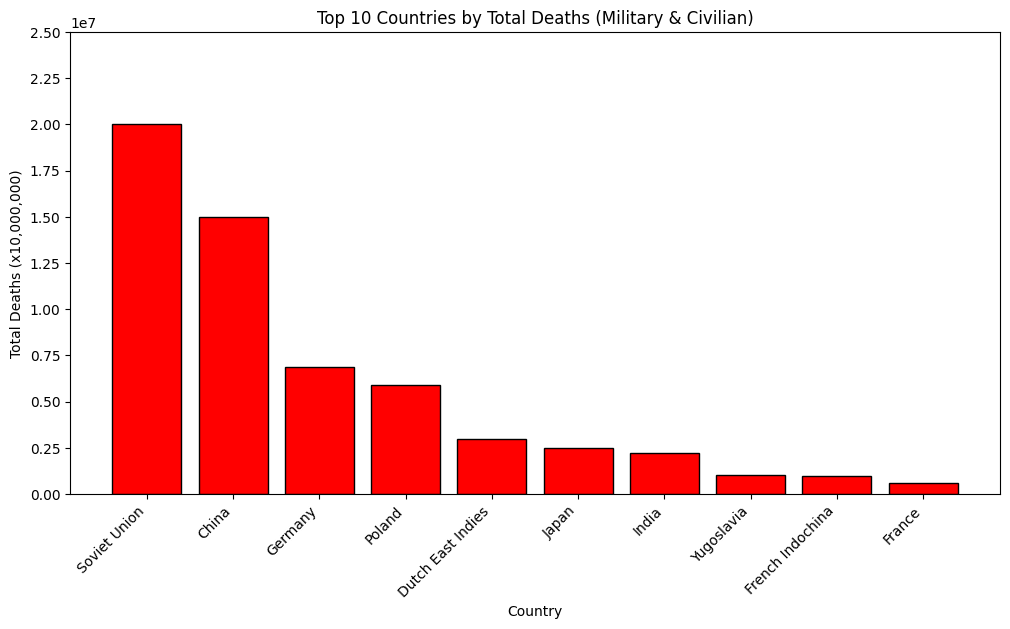

In [ ]:
# Austin Drake
# Graph of top 10 countries by total deaths

# Load the data
df = pd.read_csv(csv_path)

# Clean the 'Totaldeaths' column: remove commas, extract numbers
df['Totaldeaths'] = df['Totaldeaths'].astype(str).str.replace(',', '').str.extract(r'(\d+)')
df['Totaldeaths'] = pd.to_numeric(df['Totaldeaths'], errors='coerce')

# Drop rows with missing values in key columns
df_clean = df.dropna(subset=['Country', 'Totaldeaths'])


top = df_clean.sort_values(by='Totaldeaths', ascending=False).head(10)

plt.figure(figsize=(12, 6))
plt.bar(top['Country'], top['Totaldeaths'], color='red', edgecolor="black")
plt.xticks(rotation=45, ha='right')
plt.xlabel('Country')
plt.ylabel('Total Deaths (x10,000,000)')
plt.title('Top 10 Countries by Total Deaths (Military & Civilian)')
plt.ylim(0, 25000000)
plt.yticks(np.arange(0, 25000001, 2500000))
plt.show()


CASUALITIES: Deaths As the Percent of Population (Military & Civilian)

This visualization graphs the total deaths of each country as a percentage of that country's population. This graph shows that, though some countries may have suffered much less casualities than others, the impact could have been the same due to the country's population.

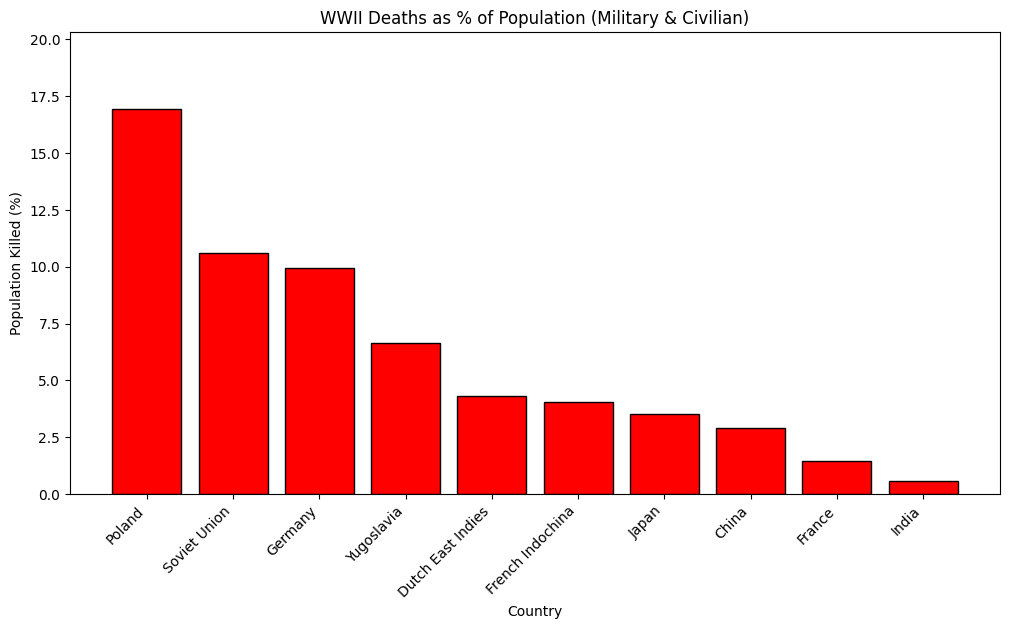

In [ ]:
# Sara Jones
# Graph of deaths as the % of population

# Load the data
df = pd.read_csv(csv_path)

# Normalize column names
df.columns = df.columns.str.lower().str.replace(' ', '').str.replace('\xa0','')

# Identify key columns
pop_col = [c for c in df.columns if 'population' in c][0]
death_col = [c for c in df.columns if 'totaldeath' in c][0]
country_col = [c for c in df.columns if 'country' in c][0]

# Clean numeric columns
for col in [pop_col, death_col]:
    df[col] = df[col].astype(str).str.replace(',', '').str.extract(r'(\d+)')
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Compute % of population killed
df['death_percent_population'] = (df[death_col] / df[pop_col]) * 100

# Filter specific countries
countries = [
    "China","Germany","Poland","Dutch East Indies","Japan",
    "India","Yugoslavia","French Indochina","France","Soviet Union"
]
df = df[df[country_col].isin(countries)]

# Sort and plot
top = df.sort_values(by='death_percent_population', ascending=False)

plt.figure(figsize=(12,6))
plt.bar(
    top[country_col],
    top['death_percent_population'],
    color='red',
    edgecolor='black'
)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Country')
plt.ylabel('Population Killed (%)')
plt.title('WWII Deaths as % of Population (Military & Civilian)')
plt.ylim(0, top['death_percent_population'].max() * 1.2)
plt.show()

CASUALTIES: Deaths As the Percent of Population (Military & Civilian)

User instructions: Input one of the ten countries used in the data set (Poland, Soviet Union, Germany, Yugoslavia, Dutch East Indies, French Indochina, Japan, China, France, India). Afterwards, the code will ouput the percentage of death in that certain country's population in World War II.

In [ ]:
# Sara Jones
# Returns total deaths as a % of population (military + civilian)

# Load the data
df = pd.read_csv(csv_path)

# Clean and normalize column names
df.columns = df.columns.str.lower().str.replace(' ', '').str.replace('\xa0','')

# Identify key columns
pop_col = [c for c in df.columns if 'population' in c][0]
death_col = [c for c in df.columns if 'totaldeath' in c][0]
country_col = [c for c in df.columns if 'country' in c][0]

# Clean numeric columns
for col in [pop_col, death_col]:
    df[col] = df[col].astype(str).str.replace(',', '').str.extract(r'(\d+)')
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Compute % of population killed
df['death_percent_population'] = (df[death_col] / df[pop_col]) * 100

# Drop rows with missing values
df_clean = df.dropna(subset=[country_col, 'death_percent_population'])

# Ask user for input
country_name = input("Enter the name of a country to see its deaths as % of population: ").strip()

# Match country name (case-insensitive)
country_data = df_clean[df_clean[country_col].str.lower() == country_name.lower()]

# Display result
if not country_data.empty:
    percent_killed = country_data['death_percent_population'].iloc[0]
    print(f"\nDeaths as % of population for {country_name}: {percent_killed:.2f}% (Military & Civilian)")
else:
    print(f"\nSorry, '{country_name}' was not found in the dataset or had no recorded data.")

Enter the name of a country to see its deaths as % of population: Poland

Deaths as % of population for Poland: 16.93% (Military & Civilian)


Average total death count (military + civilians deaths)

*Enter a country to see its total death (military + civilian) count during WWII*

*Here are some of the countries you can use as input (China, Poland, Soviet Union, Germany, and France)*

In [ ]:
# Anita Xiao
# Returns average total death count (military + civilian deaths)

# Load the data
df = pd.read_csv(csv_path)

# Clean the 'Totaldeaths' column: remove commas, extract numbers
df['Totaldeaths'] = df['Totaldeaths'].astype(str).str.replace(',', '').str.extract(r'(\d+)')
df['Totaldeaths'] = pd.to_numeric(df['Totaldeaths'], errors='coerce')

# Drop rows with missing values in key columns
df_clean = df.dropna(subset=['Country', 'Totaldeaths'])

country_name = input("Enter the name of a country to see its total casualties: ").strip()

country_casualty_data = df_clean[df_clean['Country'].str.lower() == country_name.lower()]

if not country_casualty_data.empty:
    total_deaths = country_casualty_data['Totaldeaths'].iloc[0]
    print(f"\nTotal deaths for {country_name}: {int(total_deaths):,} (Military & Civilian)")
else:
    print(f"\nSorry, '{country_name}' was not found in the dataset or had no recorded deaths.")


Enter the name of a country to see its total casualties: Poland

Total deaths for Poland: 5,900,000 (Military & Civilian)


Economic Dataset Downloaded

In [ ]:
# Download the econonmic impact dataset
path = kagglehub.dataset_download("anshul1013/monthly-war-status-economics")

# Find the CSV file (economic impact)
for file in os.listdir(path):
    if file.endswith(".csv"):
        csv_path = os.path.join(path, file)
        print(f"✅ Found CSV: {csv_path}")
        break


100%|██████████| 32.8k/32.8k [00:00<00:00, 2.20MB/s]

Extracting files...
✅ Found CSV: /root/.cache/kagglehub/datasets/anshul1013/monthly-war-status-economics/versions/1/monthly_war_dataset.csv


Average Economic Impact Factor from 1934-1949

*Enter a country name to see its average economic impact factor from September 1934 - December 1949*

*Here are some countries that can be used as input (USA, France, UK, Germany, USSR/Russia)*

In [ ]:
# Anita Xiao
#Returns Average Economic Impact Factor from 1934-1949

df = pd.read_csv(csv_path)

filtered_df = df[(df["Year"] > 1934) | ((df["Year"] == 1934) & (df["Month"] >= 9))]

country = input("Enter a country name: ").strip()

country_data = filtered_df[filtered_df["Country"].str.lower() == country.lower()]

if not country_data.empty:
    avg_factor = country_data["Economic Impact Factor"].mean()
    print(f"{country} - Average Economic Factor (1934): {avg_factor:.2f}")
else:
    print(f"Sorry, '{country}' was not found in the dataset.")


Enter a country name: Poland
Sorry, 'Poland' was not found in the dataset.


ECONOMIC IMPACTS: Average Economic Impact Factor by Country (September 1934 - December 1949)

Economic Impact Factor (0-100 scale) showing the economic strain (the higher index score shows higher economic strain)

The bar graph takes 5 countries (USA, France, UK, Germany, USSR/Russia) and finds the average economic impact factor over the course of WW2 (1934-1949).

This graph helps show that each country had significant economic stress over the course of WW2.

Using Colab cache for faster access to the 'monthly-war-status-economics' dataset.


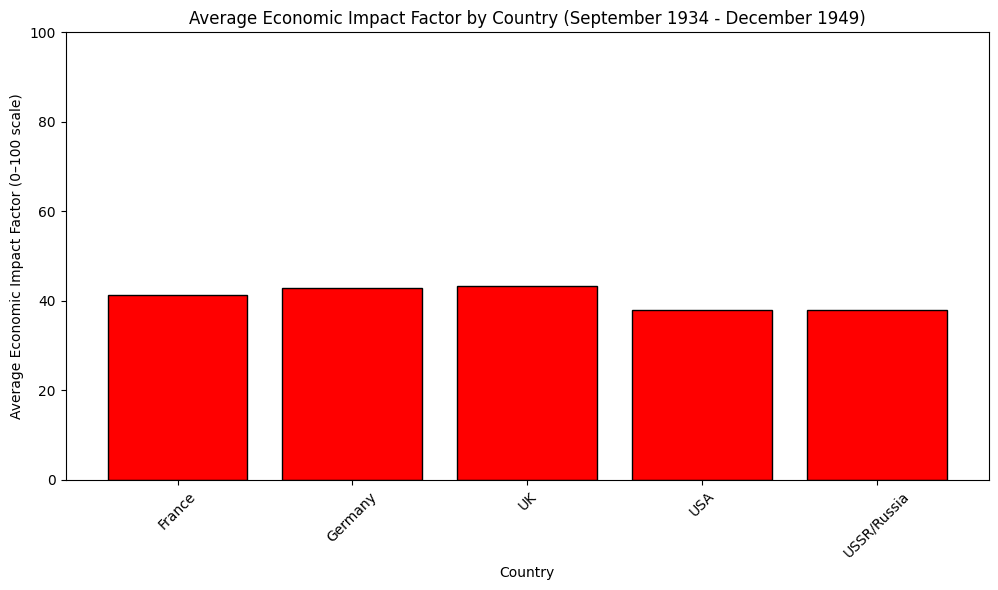

In [ ]:
# Brayden Jones
# Graph of average economic impact factor by country

# Download the econonmic impact dataset
path = kagglehub.dataset_download("anshul1013/monthly-war-status-economics")

# Load the data
df = pd.read_csv(csv_path)

# Filter data to Year >= 1934 and Month >= 9
filtered_df = df[(df["Year"] > 1934) | ((df["Year"] == 1934) & (df["Month"] >= 9))]

# Group by Country and take the AVERAGE Economic Impact Factor
country_impacts = (
    filtered_df.groupby("Country")["Economic Impact Factor"]
    .mean()
    .reset_index()
)

# Plot the average Economic Impact Factor per country
plt.figure(figsize=(10,6))
plt.bar(
    country_impacts["Country"],
    country_impacts["Economic Impact Factor"],
    color="red",
    edgecolor="black"
)
plt.xlabel("Country")
plt.ylabel("Average Economic Impact Factor (0–100 scale)")
plt.title("Average Economic Impact Factor by Country (September 1934 - December 1949)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.ylim(0, 100)
plt.show()

ECONOMIC IMPACT: Economic Impact Factor Over Time

This visualization is meant to portray the economic impact throughout World War II and the four years that followed. The graph depicts the economic impact on a scale of 0-100 on the y-axis and the years of the war on the x-axis. The visual helps to express the severity war has on economies and the lasting effect that it has after the war.

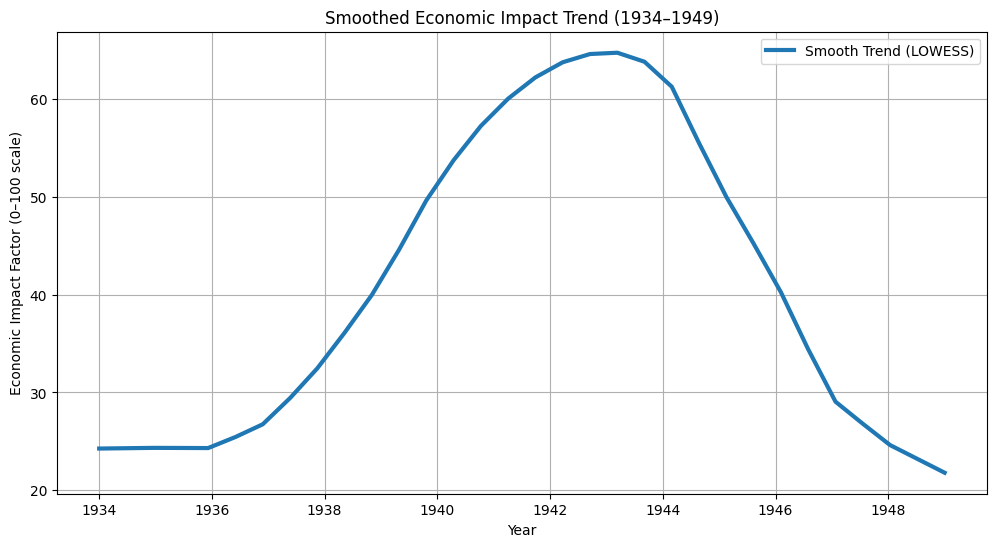

In [ ]:
# Rylan Lottes
# Graph to show economic impact from 1934-1949

# Load the dataset
df_economic = pd.read_csv(csv_path)

# Convert date columns
df_economic['Date'] = pd.to_datetime(
    df_economic['Year'].astype(str) + '-' + df_economic['Month'].astype(str),
    format='%Y-%m'
)

# Filter time frame
filtered_df = df_economic[
    (df_economic["Year"] >= 1934) & (df_economic["Year"] <= 1949)
]

# One point per year
yearly_df = (
    filtered_df.groupby("Year")["Economic Impact Factor"]
    .mean()
    .reset_index()
)

# Convert to ordinal dates
yearly_df["Date"] = pd.to_datetime(yearly_df["Year"], format="%Y")
x_years = yearly_df["Date"].map(pd.Timestamp.toordinal)
y_vals = yearly_df["Economic Impact Factor"]

# ---- DOUBLE the number of points ----
x_dense = np.linspace(x_years.min(), x_years.max(), len(x_years) * 2)

# ---- LOWESS smoothing ----
lowess_curve = lowess(y_vals, x_years, frac=0.4)
x_lowess = lowess_curve[:, 0]
y_lowess = lowess_curve[:, 1]

# Interpolate LOWESS onto dense x values
y_dense = np.interp(x_dense, x_lowess, y_lowess)

# Convert ordinals → datetime safely
dense_dates = [datetime.fromordinal(int(x)) for x in x_dense]

# Plot ONLY the smooth trend line
plt.figure(figsize=(12,6))
plt.plot(dense_dates, y_dense, label="Smooth Trend (LOWESS)", linewidth=3)

plt.xlabel("Year")
plt.ylabel("Economic Impact Factor (0–100 scale)")
plt.title("Smoothed Economic Impact Trend (1934–1949)")
plt.grid(True)
plt.legend()
plt.show()
